# 01 — 晶体结构 → 粉末 XRD 模拟：Si / Al / α-Fe

**Open Materials Lab · Increment 1** — 教学模拟 (teaching simulation)，**不是实验测量 (not experimental data)**。

流程：COD 晶体结构 (CIF) → 自写 CIF 解析与对称展开 → 晶面间距 $d_{hkl}$ → Bragg 角 $2\theta$ →
原子散射因子 $f_0(s)$ (Cromer–Mann, Int. Tables Vol. C) → 结构因子 $F_{hkl}$ → 多重性 + Lorentz–polarization → 粉末花样；
最后与 **pymatgen `XRDCalculator`** 交叉验证。

模型假设：无 Debye–Waller 因子 ($B=0$)、无吸收、无择优取向、无 Kα2、无仪器函数、无反常色散。

## 1. 公式 (formulas)

- 度规张量 (metric tensor)：$G_{ij} = \mathbf a_i\cdot\mathbf a_j$，$\;1/d_{hkl}^2 = \mathbf h^{T} G^{-1}\mathbf h$；立方晶系 $d = a/\sqrt{h^2+k^2+l^2}$
- Bragg 定律：$\lambda = 2d\sin\theta$，$\lambda_{\mathrm{Cu\,K\alpha_1}} = 1.5406$ Å
- 原子散射因子：$f_0(s) = \sum_{i=1}^{4} a_i e^{-b_i s^2} + c$，$s = \sin\theta/\lambda = 1/(2d)$
- 结构因子：$F_{hkl} = \sum_j f_j\, e^{2\pi i (h x_j + k y_j + l z_j)}$
- 粉末强度：$I \propto \sum_{\text{equiv. } hkl} |F_{hkl}|^2 \cdot \mathrm{LP}(\theta)$，$\mathrm{LP} = \dfrac{1+\cos^2 2\theta}{\sin^2\theta\cos\theta}$

**系统消光 (systematic extinctions)**，单原子基元：
- BCC：$F = f[1+(-1)^{h+k+l}]$ → 仅 $h+k+l$ 为偶数时出现
- FCC：$F = f[1+(-1)^{h+k}+(-1)^{h+l}+(-1)^{k+l}]$ → $h,k,l$ 全奇或全偶
- 金刚石 (diamond)：$F = F_{\mathrm{FCC}}\,[1+i^{\,h+k+l}]$ → 全奇，或全偶且 $h+k+l = 4n$；因此 (200)、(222) 在球形原子模型中为零

In [1]:
import os, sys
ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "src"))
import numpy as np
import xtal
from xtal import read_cif, d_spacing, bragg_two_theta, structure_factor, f0_cromer_mann, powder_peaks, is_allowed, CU_KA1
from xtal.compare import compare, pymatgen_form_factor
CIFS = {"Si": "data/Si_COD_9011998.cif", "Al": "data/Al_COD_9012002.cif", "Fe": "data/Fe_COD_9008536.cif"}
KIND = {"Si": "diamond", "Al": "fcc", "Fe": "bcc"}
X = {el: read_cif(os.path.join(ROOT, p), el) for el, p in CIFS.items()}
for el, x in X.items():
    print(f"{el}: a = {x.a} Å, space group {x.spacegroup!r}, atoms in cell = {x.n_atoms}")
    print(np.round(x.frac_coords, 4))

Si: a = 5.430941 Å, space group 'F d -3 m :1', atoms in cell = 8
[[0.   0.   0.  ]
 [0.   0.5  0.5 ]
 [0.5  0.   0.5 ]
 [0.5  0.5  0.  ]
 [0.75 0.75 0.25]
 [0.75 0.25 0.75]
 [0.25 0.75 0.75]
 [0.25 0.25 0.25]]
Al: a = 4.04961 Å, space group 'F m -3 m', atoms in cell = 4
[[0.  0.  0. ]
 [0.  0.5 0.5]
 [0.5 0.  0.5]
 [0.5 0.5 0. ]]
Fe: a = 2.8665 Å, space group 'I m -3 m', atoms in cell = 2
[[0.  0.  0. ]
 [0.5 0.5 0.5]]


## 2. 低指数晶面：$d$、$2\theta$、$|F|$ 与消光判断

In [2]:
hkls = [(1,0,0),(1,1,0),(1,1,1),(2,0,0),(2,1,0),(2,1,1),(2,2,0),(2,2,2),(3,1,1),(4,0,0)]
for el, x in X.items():
    print(f"\n{el} ({KIND[el]})   hkl    d(Å)     2θ(°)    |F|      rule")
    for h in hkls:
        d = d_spacing(h, x.cell); s = 1/(2*d)
        F = structure_factor(x, [h], [s])[0]
        print(f"        {''.join(map(str,h))}  {d:7.4f}  {bragg_two_theta(d, CU_KA1):8.4f}  {abs(F):7.3f}   {'allowed' if is_allowed(h, KIND[el]) else 'FORBIDDEN'}")


Si (diamond)   hkl    d(Å)     2θ(°)    |F|      rule
        100   5.4309   16.3081    0.000   FORBIDDEN
        110   3.8403   23.1424    0.000   FORBIDDEN
        111   3.1356   28.4424   59.600   allowed
        200   2.7155   32.9588    0.000   FORBIDDEN
        210   2.4288   36.9818    0.000   FORBIDDEN
        211   2.2172   40.6597    0.000   FORBIDDEN
        220   1.9201   47.3028   69.743   allowed
        222   1.5678   58.8564    0.000   FORBIDDEN
        311   1.6375   56.1225   46.214   allowed
        400   1.3577   69.1301   60.101   allowed

Al (fcc)   hkl    d(Å)     2θ(°)    |F|      rule
        100   4.0496   21.9308    0.000   FORBIDDEN
        110   2.8635   31.2102    0.000   FORBIDDEN
        111   2.3380   38.4724   35.823   allowed
        200   2.0248   44.7209   34.037   allowed
        210   1.8110   50.3438    0.000   FORBIDDEN
        211   1.6532   55.5411    0.000   FORBIDDEN
        220   1.4318   65.0968   29.268   allowed
        222   1.1690   8

## 3. 原子散射因子 $f_0(s)$ — 本项目 (Int. Tables Vol. C) vs pymatgen 内置表

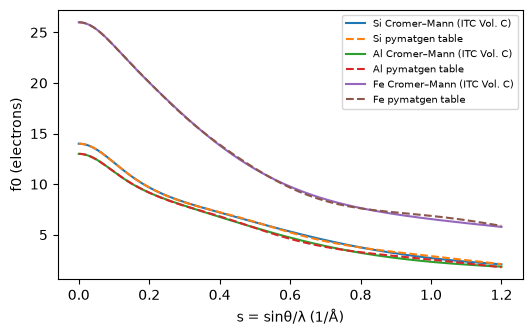

In [3]:
import matplotlib.pyplot as plt
s = np.linspace(0, 1.2, 200)
fig, ax = plt.subplots(figsize=(6,3.5))
for el in X:
    ax.plot(s, f0_cromer_mann(el, s), label=f"{el} Cromer–Mann (ITC Vol. C)")
    ax.plot(s, pymatgen_form_factor(el, s), "--", label=f"{el} pymatgen table")
ax.set_xlabel("s = sinθ/λ (1/Å)"); ax.set_ylabel("f0 (electrons)"); ax.legend(fontsize=7); plt.show()

## 4. 粉末 XRD 交叉验证 (own code vs pymatgen)
`ΔI(same f)`：把 pymatgen 的 $f(s)$ 代入本代码后的强度差 —— 用于定位差异来源。

In [4]:
for el, x in X.items():
    rows, own, pat = compare(x, os.path.join(ROOT, CIFS[el]), CU_KA1, (10, 120))
    rows2, _, _ = compare(x, os.path.join(ROOT, CIFS[el]), CU_KA1, (10, 120), form_factor=pymatgen_form_factor)
    print(f"\n{el}: {len(own)} peaks (own) vs {len(pat.x)} peaks (pymatgen)")
    print(" hkl       mult   2θ_own    2θ_pmg     Δ2θ       I_own   I_pmg    ΔI    ΔI(same f)")
    for r, r2 in zip(rows, rows2):
        print(f" {r['hkl']:9s} {r['mult']:4d} {r['tt_own']:9.4f} {r['tt_pmg']:9.4f} {r['dtt']:9.1e} {r['I_own']:7.2f} {r['I_pmg']:7.2f} {r['dI']:+6.2f}   {r2['dI']:+.1e}")


Si: 9 peaks (own) vs 9 peaks (pymatgen)
 hkl       mult   2θ_own    2θ_pmg     Δ2θ       I_own   I_pmg    ΔI    ΔI(same f)
 111          8   28.4424   28.4424   0.0e+00  100.00  100.00  +0.00   +0.0e+00
 220         12   47.3028   47.3028   0.0e+00   67.11   66.66  +0.45   +2.8e-14
 311         24   56.1225   56.1225   0.0e+00   39.94   39.59  +0.35   -2.8e-14
 400          6   69.1301   69.1301   0.0e+00   10.70   10.71  -0.02   +0.0e+00
 331         24   76.3764   76.3764   0.0e+00   16.19   16.34  -0.15   -7.1e-15
 422         24   88.0304   88.0304  -2.8e-14   23.14   23.49  -0.35   +3.6e-15
 511+333     32   94.9527   94.9527   1.4e-14   13.56   13.73  -0.17   -8.9e-15
 440         12  106.7088  106.7088   0.0e+00    9.18    9.18  -0.01   -1.8e-15
 531         48  114.0925  114.0925   0.0e+00   18.39   18.24  +0.16   -7.1e-15

Al: 8 peaks (own) vs 8 peaks (pymatgen)
 hkl       mult   2θ_own    2θ_pmg     Δ2θ       I_own   I_pmg    ΔI    ΔI(same f)
 111          8   38.4724   38.4

## 5. 图 (figures) — 由 `scripts/run_validation.py` 生成，并在此重新生成

Si: 9 peaks, max|Δ2θ|=2.84e-14°, max|ΔI|=0.446, max|ΔI same f|=2.8e-14
Al: 8 peaks, max|Δ2θ|=5.68e-14°, max|ΔI|=0.778, max|ΔI same f|=2.1e-14
Fe: 5 peaks, max|Δ2θ|=4.26e-14°, max|ΔI|=0.461, max|ΔI same f|=1.8e-14



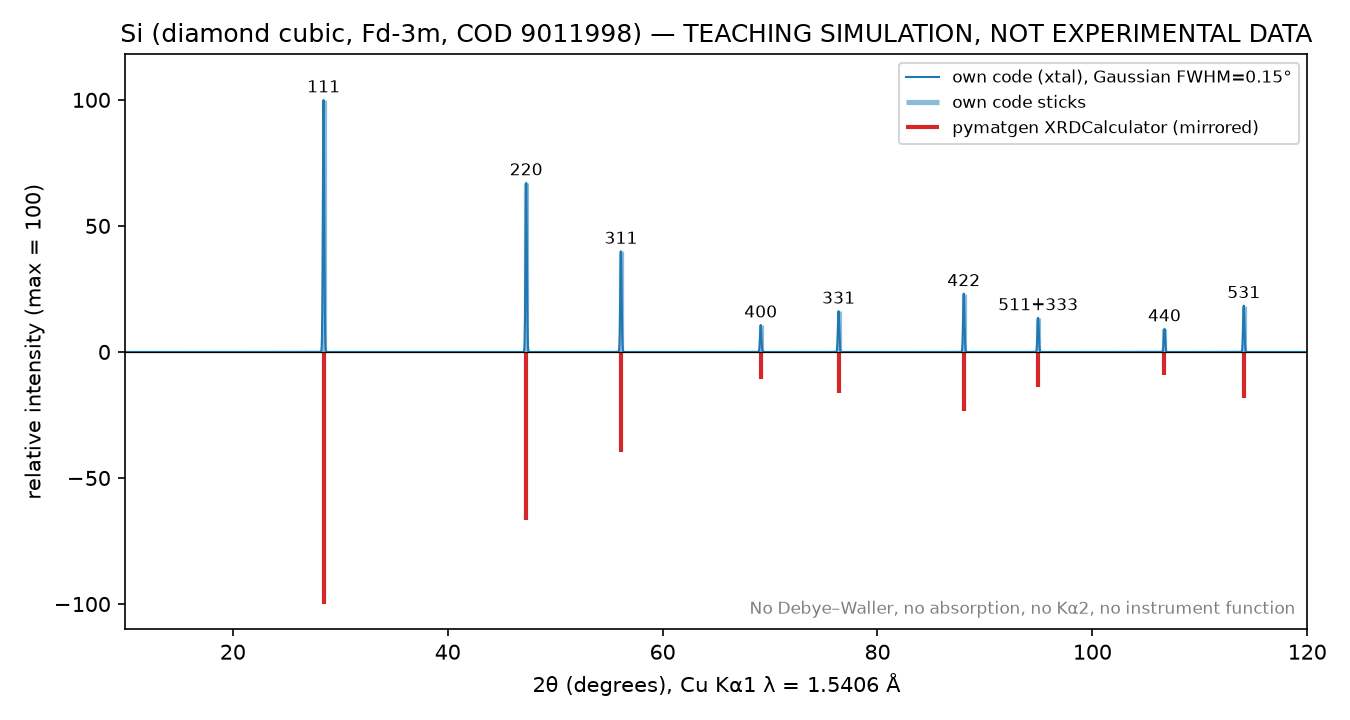

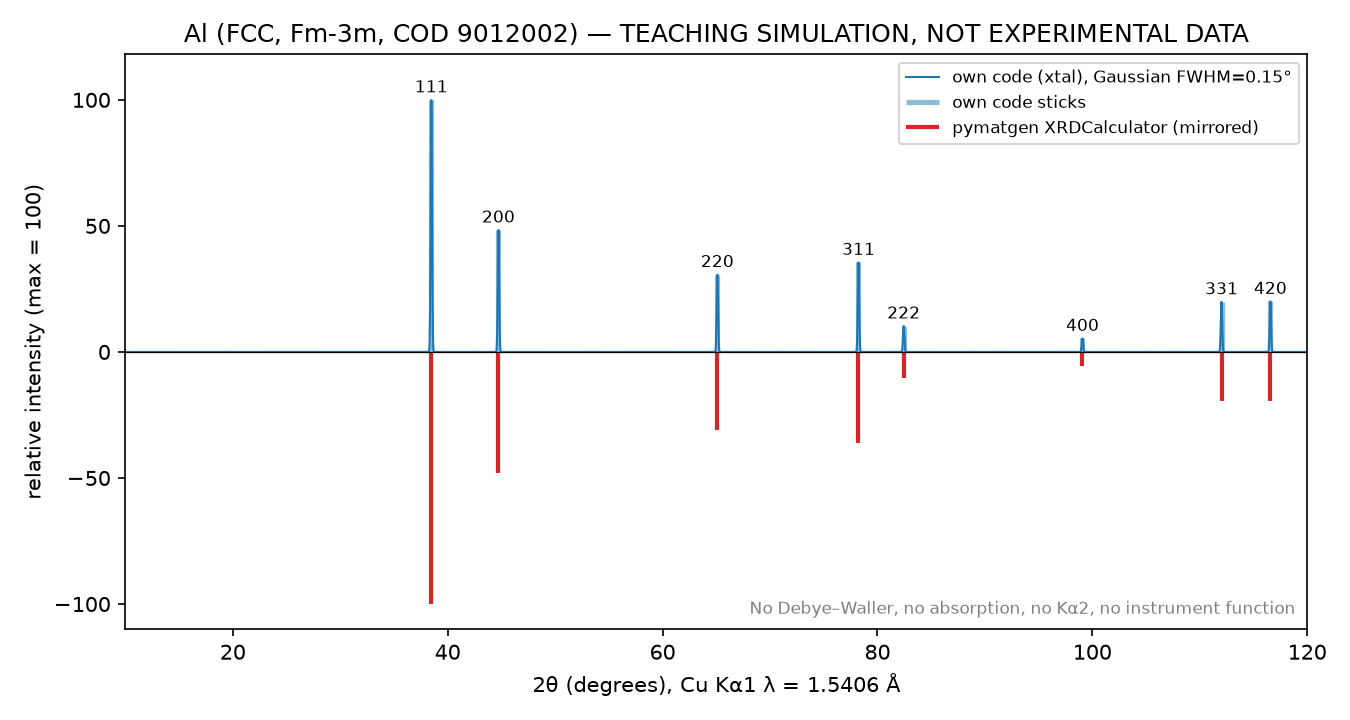

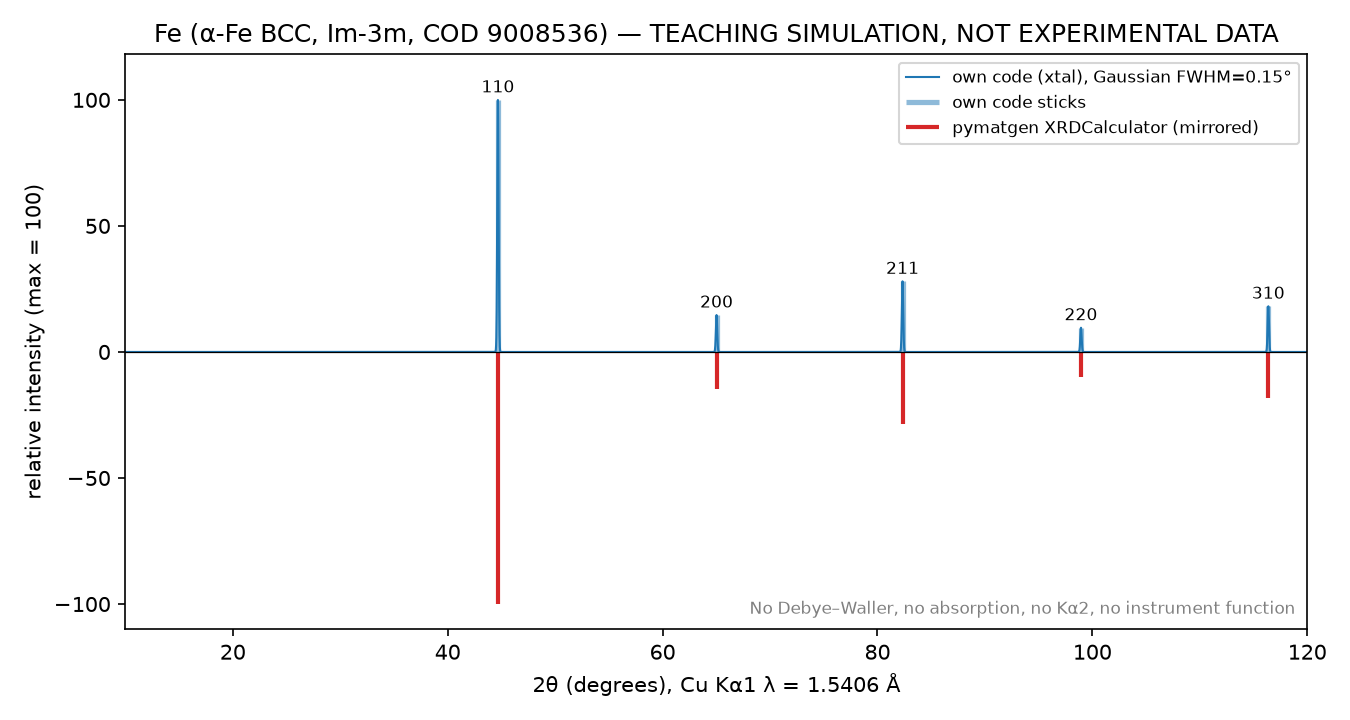

In [5]:
import subprocess
print(subprocess.run([sys.executable, os.path.join(ROOT, "scripts", "run_validation.py")], capture_output=True, text=True).stdout)
from IPython.display import Image, display
for el in X:
    display(Image(filename=os.path.join(ROOT, "figures", f"{el}_xrd_own_vs_pymatgen.png")))

## 6. 结论与局限 (conclusions & limitations)

- 峰位 $2\theta$：本代码与 pymatgen 在全部峰上一致到浮点舍入 (~1e-13°)，两者都由同一 CIF 晶格常数 + Bragg 定律决定。
- 相对强度：差异 < 1 (满分 100)，来源是**原子散射因子表不同**；把 pymatgen 的 $f(s)$ 代入本代码后，差异降到 ~1e-14，说明结构因子、多重性、LP 因子的实现一致。
- 消光规则：FCC/BCC/金刚石的解析规则与数值 $F_{hkl}$ 在 $0\le h,k,l\le5$ 全部一致。
- **这是教学模拟**：未含 Debye–Waller、吸收、Kα2、仪器展宽、择优取向；高角峰强度会系统性偏高。Si(222) 在真实晶体中有很弱的"禁戒"反射，球形原子模型无法给出。
- 与实验数据 (如 ICDD PDF 卡片或 NIST SRM 640 系列) 的比较尚未进行，留待后续增量。